## Introducción

Este cuaderno realiza un **barrido paramétrico** sobre el parámetro $\lambda$ que controla la tasa de recuperación exponencial de $D(z)$ desde la superficie hacia el bulk:

$$D(z) = D_s + (D_0 - D_s)\left[\left(1 - e^{-\lambda(z-d)}\right)(1 - S(z)) + S(z)\right].$$

Un $\lambda$ pequeño implica que $D(z)$ recupera lentamente el valor $D_0$, creando una zona superficial de baja difusividad extensa. Un $\lambda$ grande equivale a una transición casi inmediata. Se barren seis valores: $\lambda \in \{0.001,\, 0.01,\, 0.05,\, 0.1,\, 1.0,\, 10.0\}\,\text{nm}^{-1}$.

Parámetros fijos: $d = 15\,\text{nm}$, $R = L = 750\,\text{nm}$, $\delta = 2d/3$, $z_c = 0.75 L/d$, $\kappa = 0$.

In [1]:
import os
import numpy as np
from scipy.special import jv
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.linalg import eigh_tridiagonal
from scipy.sparse import diags
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from joblib import Parallel, delayed
import pandas as pd
import matplotlib.pyplot as plt
import multiprocessing as mp

In [2]:
# -----------------------------------------------------------------------------
# 0. Crear carpeta para archivos temporales (si no existe)
# -----------------------------------------------------------------------------
if not os.path.isdir("data/temp_G_lambda"):
    os.makedirs("data/temp_G_lambda")

In [3]:
# -----------------------------------------------------------------------------
# 1. Parámetros físicos (en nm y unidades compatibles)
# -----------------------------------------------------------------------------
# Profundidad del NV (nm)
d = 15  
# Coeficientes de difusión
D0 = 2e3        # nm²/s (equiv. a 2e-9 m²/µs)
D_s = 2e1       # nm²/s
# Geometría
R = L = 50 * d 
z_c=0.75*L/d
delta = 2 * d / 3  
# Parámetro κ fijo (nm/s)
varkappa = 0.0  
# Modos y nodos
n_modes_radial = 100
m_max = 100
N_quad = 1000   # para integración numérica
# Parámetros de malla en z
N_z = 45000
alpha_grid = 5.0

In [4]:
# -----------------------------------------------------------------------------
# 2. Malla adaptativa en z y perfil D(z) (NO depende de varkappa)
# -----------------------------------------------------------------------------
# 2.1 Construcción de la malla en z
j_vals = np.arange(N_z)
z = d + L * np.sinh(alpha_grid * j_vals / (N_z - 1)) / np.sinh(alpha_grid)
h = np.diff(z)  # h_j = z[j] - z[j-1]

# 2.2 Definición de D(z) (función)
def D(z_val,lambda_param):
    """
    Perfil de difusión completo con z en nm:
    D(z) = D_s + (D0 - D_s) * [ (1 - exp(-lambda_param*(z - d))) * (1 - S(z)) + S(z) ],
    con S(z) = 0.5 * [1 + tanh( (z - (z_c + d)) / delta ) ].
    """
    S = 0.5 * (1 + np.tanh((z_val - (z_c + d)) / delta))
    return D_s + (D0 - D_s) * ((1 - np.exp(-lambda_param * (z_val - d))) * (1 - S) + S)

In [5]:
# -----------------------------------------------------------------------------
# 3. Definición de funciones compartidas:
#    - robin_eq(alpha): ecuación trascendental radial con parámetro varkappa
#    - R_func(alpha_array, rho_array): calcula los modos radiales J0(alpha_n * rho) normalizados
#    - build_system(n): ensambla y diagonaliza la parte axial para un modo radial n
# -----------------------------------------------------------------------------
def robin_eq(alpha, D_eff):
    """
    Ecuación trascendental radial para hallar raíces alpha_n:
       alpha * J1(alpha*R) - (varkappa / D_eff) * J0(alpha*R) = 0.
    """
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

def find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4):
    """
    Encuentra las primeras `n_roots` raíces alpha_n de robin_eq(alpha)=0
    en intervalos [0, ...] usando brentq y un paso `step`.
    """
    alpha_roots = []
    alpha_current = 0.0
    while len(alpha_roots) < n_roots:
        try:
            root = brentq(lambda a: robin_eq(a, D_eff),
                          alpha_current, alpha_current + step, xtol=1e-6)
            alpha_roots.append(root)
            alpha_current = root + step
        except ValueError:
            alpha_current += step
    return np.array(alpha_roots)

def R_func(alpha_arr, rho_arr):
    """
    Calcula los modos radiales normalizados R_n(rho) = J0(alpha_n * rho)/sqrt(norm_n).
    Retorna:
      - R_normed: array con forma (n_modes_radial, len(rho_arr))
      - norms: vector con las normas (no se usa más adelante, pero lo dejamos para consistencia)
    """
    # alpha_arr: (n_modes_radial,)
    # rho_arr: (N_rhos,)
    alpha = alpha_arr.reshape(-1, 1)   # forma (n_modes_radial, 1)
    rho = rho_arr.reshape(1, -1)       # forma (1, N_rhos)
    R_matrix = jv(0, alpha * rho)      # (n_modes_radial, N_rhos)

    # Cálculo de normas analíticas: norms[n] = sqrt{ \int_0^R rho J0^2(alpha_n rho) d rho }
    J0R = jv(0, alpha_arr * R)  # (n_modes_radial,)
    J1R = jv(1, alpha_arr * R)  # (n_modes_radial,)
    norms = 0.5 * R ** 2 * (J0R**2 + J1R**2)  # (n_modes_radial,)
    norms = np.atleast_1d(norms)
    Nnorm = 1.0 / np.sqrt(norms)  # factor de normalización

    R_normed = Nnorm[:, None] * R_matrix  # (n_modes_radial, N_rhos)
    return R_normed, np.sqrt(norms)

def build_system(n, alpha_n, D_values, z, h):
    """
    Ensambla y diagonaliza la parte axial para el modo radial n.

    Discretizacion en VOLUMEN FINITO sobre la malla no uniforme: integrando
    -d/dz(D dZ/dz) + alpha^2 D Z = Lambda Z sobre la celda [z_{j-1/2}, z_{j+1/2}]
    de ancho w_j se obtiene el problema generalizado SIMETRICO K Z = Lambda M Z,
    con M = diag(w_j) y

        K[j,j+1] = K[j+1,j] = -D_{j+1/2} / h_j
        K[j,j]   = D_{j-1/2}/h_{j-1} + D_{j+1/2}/h_j + alpha^2 D_j w_j

    Las celdas de los extremos son MEDIAS celdas (w_0 = h_0/2, w_{N-1} = h_{N-2}/2);
    en z = d va la condicion de Robin (+ varkappa) y en z = d+L la de Neumann.
    El sistema se simetriza con A = M^(-1/2) K M^(-1/2) y se diagonaliza con
    eigh_tridiagonal.

    Sustituye al ensamblado anterior, que (a) escribia lower_diag[-2] en vez de
    lower_diag[-1], dejando el ultimo nodo desacoplado y rompiendo la conservacion
    de masa, (b) dividia las filas de frontera por h_0 en vez de h_0/2, y
    (c) aplicaba varkappa tambien en z = d+L. Ademas evita ARPACK en modo
    shift-invert con sigma=0 sobre una matriz singular, que no convergia.

    Retorna: (n, (evals, evecs)) con evals los m_max autovalores mas bajos y
    evecs (N_z, m_max) normalizados con int Z^2 dz = 1.
    """
    alpha = alpha_n[n]
    N = len(z)

    # Anchos de celda (= pesos de la regla del trapecio)
    w_cell = np.empty(N)
    w_cell[1:-1] = 0.5 * (h[:-1] + h[1:])
    w_cell[0]    = 0.5 * h[0]
    w_cell[-1]   = 0.5 * h[-1]

    # Media armonica de D en las interfases j+1/2
    D_half = 2.0 * D_values[:-1] * D_values[1:] / (D_values[:-1] + D_values[1:])

    K_dia = np.zeros(N)
    K_dia[1:-1] = D_half[:-1] / h[:-1] + D_half[1:] / h[1:]
    K_dia[0]    = D_half[0] / h[0] + 0.0              # Robin en z = d
    K_dia[-1]   = D_half[-1] / h[-1]            # Neumann en z = d + L
    K_dia += alpha**2 * D_values * w_cell
    K_off = -D_half / h

    s = 1.0 / np.sqrt(w_cell)
    evals, V = eigh_tridiagonal(K_dia * s * s, K_off * s[:-1] * s[1:],
                                select='i', select_range=(0, m_max - 1))

    evecs = V * s[:, None]
    evecs /= np.sqrt(np.einsum('j,jm,jm->m', w_cell, evecs, evecs))[None, :]

    return (n, (np.maximum(evals, 0.0), evecs))

def T(t, lam):
    return np.exp(-np.abs(lam) * t)

def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return S.T # np.maximum(S.T, 0)

In [6]:
# -----------------------------------------------------------------------------
# 4. Valores de varkappa a barrer (en nm/s)
# -----------------------------------------------------------------------------
lambda_list = [0.001, 0.01, 0.05, 0.1, 1.0, 10.0]

In [7]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de J0(alpha_n * rho) y demás datos independientes
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
# N_quad = 1000
# rho_nodes = np.linspace(0.0, R, N_quad)  # np.linspace(0,R,N_quad)
# z_nodes = np.linspace(d, L + d, N_quad)   # en [d, L+d]
# rho0 = 0.0
# z0 = d
# dr = rho_nodes[1] - rho_nodes[0]
# dz = z_nodes[1] - z_nodes[0]

# # 5.4 Matriz f_mat (factor dipolar) es independiente de varkappa:
# R2 = rho_nodes**2
# Z2 = z_nodes**2             # z_nodes ya empieza en d (distancia al NV)
# f_mat = (3 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # forma (N_quad, N_quad)
# f0_mat = (3*z0**2-rho0**2)/(rho0**2+z0**2)**2.5
# rho_factor = (rho_nodes[:, None] * f0_mat * f_mat * dr * dz)

# # 5.5 Vector de tiempos t en los que se evaluará G(t)
# t_values = np.logspace(-3, 7, N_quad)   # forma (N_quad,)

In [8]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de f(ρ,z) y medida ρ dρ dz (independientes de λ)
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
# Malla de cuadratura para las integrales modales F_nm.
# El integrando esta muy concentrado cerca de la superficie: f decae como z^-3 y
# los modos axiales tienen capa limite ahi. Con malla uniforme y suma rectangular
# (dr*dz*sum) la suma modal (5/16pi) sum F_nm^2 llegaba a superar a la integral
# directa (5/16pi) int f^2 rho drho dz, imposible para Parseval truncada.
# Se agrupan nodos en la superficie con la misma transformacion sinh de la malla
# axial y se usan pesos del trapecio.
N_quad = 2000
_s = np.arange(N_quad) / (N_quad - 1)
rho_nodes = np.linspace(0.0, R, N_quad)
z_nodes   = d + L * np.sinh(alpha_grid * _s) / np.sinh(alpha_grid)    # [d, d+L], apretada en z=d
def pesos_trapecio(x):
    """Pesos de la regla del trapecio para una malla posiblemente no uniforme."""
    h = np.diff(x)
    w = np.empty_like(x)
    w[1:-1] = 0.5 * (h[:-1] + h[1:])
    w[0]    = 0.5 * h[0]
    w[-1]   = 0.5 * h[-1]
    return w


w_rho = pesos_trapecio(rho_nodes)
w_z   = pesos_trapecio(z_nodes)


# 5.2 Factor dipolar f(ρ,z) en la malla (N_quad, N_quad)
R2 = rho_nodes**2
Z2 = z_nodes**2             # z_nodes ya empieza en d (distancia al NV)
# Kernel dipolar: f = (3cos^2(theta) - 1)/r^3 con cos(theta)=z/r, r^2=rho^2+z^2,
# es decir f = (3z^2 - r^2)/r^5 = (2z^2 - rho^2)/(rho^2+z^2)^{5/2}.
# (Antes: 3z^2 - rho^2; la resta va contra r^2, no contra rho^2. El prefactor
#  5/(16 pi) es [ (1/4)sqrt(5/pi) ]^2, el coeficiente de Y_2^0 al cuadrado.)
f_mat = (2 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # (Nr, Nz)

# 5.3 Medida cilíndrica ρ dρ dz
# medida rho drho dz con pesos del trapecio en ambas direcciones
measure = (rho_nodes * w_rho)[:, None]      # (Nr, 1)

# 5.4 Matriz F(ρ,z) = ρ dρ dz f(ρ,z)
F = measure * f_mat * w_z[None, :]                         # (Nr, Nz)

# 5.5 Vector de tiempos t en los que se evaluará G(t)
t_values = np.logspace(-3, 7, N_quad)      # (N_quad,)

In [9]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada lambda_param, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
# D_eff_vals=[]
# for lam in lambda_list:
#     print(f"--- λ = {lam:.4f} nm⁻¹ ---")
    
#     # 6.1 Recalcular D(z) y D_eff
#     D_values = D(z, lam)
#     integral_D = np.trapezoid(1.0 / D_values, z)
#     D_eff = L / integral_D
#     D_eff_vals.append(D_eff)

#     # 6.1. Hallar raíces alpha_n (n_modes_radial valores)
#     alpha_n = find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4)

#     # 6.2. Modos radiales normalizados en nodos rho
#     R0_mat, _ = R_func(alpha_n, rho_nodes)  # (n_modes_radial, N_quad)

#     # 6.3. Resolver la parte axial en paralelo para cada modo radial n
#     mp.set_start_method('spawn', force=True)
#     axial_results = Parallel(n_jobs=4, verbose=1)(
#         delayed(build_system)(n, alpha_n, D_values, z, h)
#         for n in range(n_modes_radial))

#     # Recolectar autovalores y autovectores
#     eigenvalues_ax = {}
#     eigenvectors_ax = {}
#     for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
#         eigenvalues_ax[n] = evals
#         eigenvectors_ax[n] = evecs
#     del axial_results
    
#     eigenvalues_ax = np.array([
#         [eigenvalues_ax[n][m] for m in range(m_max)]
#         for n in range(n_modes_radial)
#     ])

#     eigenvectors_ax = np.array([
#         [eigenvectors_ax[n][:,m] for m in range(m_max)]
#         for n in range(n_modes_radial)
#     ])

#     # 6.4. Normalizar cada modo axial en z (∫ Z^2 dz = 1)
#     norms_ax = np.sqrt(np.trapezoid(eigenvectors_ax**2, z, axis=2))  # (n_modes_radial, m_max)
#     norms_ax[norms_ax == 0] = 1.0
#     eigenvectors_ax /= norms_ax[:, :, None]
#     del norms_ax
#     # 6.5. Construir interpoladores cúbicos para Z_{n,m}(z) en z_nodes
#     Z_interps = np.empty((n_modes_radial, m_max), dtype=object)
#     for n in range(n_modes_radial):
#         for m in range(m_max):
#             Z_interps[n, m] = CubicSpline(z, eigenvectors_ax[n, m, :], extrapolate=False)

#     # 6.6. Condición inicial tipo delta en (rho0, z0):
    
#     # 6.6.1 Evaluar R_n(rho0)
#     R0_pt, _ = R_func(alpha_n, np.array([rho0]))  # (n_modes_radial, 1)
#     R0_pt = R0_pt[:, 0]  # (n_modes_radial,)

#     # 6.6.2 Evaluar Z_{n,m}(z0)
#     Z0 = np.empty((n_modes_radial, m_max))
#     for n in range(n_modes_radial):
#         for m in range(m_max):
#             Z0[n, m] = Z_interps[n, m](z0)

#     # 6.6.3 Coeficientes A_{n,m}
#     A_nm = R0_pt[:, None] * Z0   # (n_modes_radial, m_max)

#     # 6.8. Construcción de Z_tens[j, n, m] = Z_{n,m}(z_nodes[j])
#     Z_tens = np.empty((N_quad, n_modes_radial, m_max))
#     for n in range(n_modes_radial):
#         for m in range(m_max):
#             Z_tens[:, n, m] = Z_interps[n, m](z_nodes)
    
#     G_values = np.zeros_like(t_values)
#     for i,t_val in enumerate(t_values):
#         S=compute_P_vec(t_val,eigenvalues_ax,Z_tens, R0_mat, A_nm).T
#         integrand = rho_factor * S  # (Nr, Nz) * (Nr, Nz)
        
#         G_values[i] = (5/(16*np.pi)) * np.sum(integrand)

#     # -----------------------------------------------------------------------------
#     # 6.15. Guardar G_values en un archivo temporal y liberar memoria
#     # -----------------------------------------------------------------------------
#     temp_filename = os.path.join("data/temp_G_lambda", f"G_lambda_{lam}.dat")
#     # Preparamos un array de dos columnas: [t_values, G_values]
#     data_to_save = np.column_stack([t_values, G_values])  # (N_quad, 2)
#     header_str = "Tiempo(s)   G_lam{}".format(lam)

#     np.savetxt(
#         temp_filename,
#         data_to_save,
#         header=header_str,
#         fmt="%.9e",
#         comments=''
#     )

#     # Liberamos G_values inmediatamente
#     del G_values
#     del data_to_save

#     print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")

In [10]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada lambda_param, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
D_eff_vals = []

for lam in lambda_list:
    print(f"--- λ = {lam:.4f} nm⁻¹ ---")
    
    # 6.1 Recalcular D(z) y D_eff
    D_values = D(z, lam)
    integral_D = np.trapezoid(1.0 / D_values, z)
    D_eff = L / integral_D
    D_eff_vals.append(D_eff)

    # 6.2. Hallar raíces alpha_n (n_modes_radial valores)
    alpha_n = find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4)

    # 6.3. Modos radiales normalizados en nodos rho_nodes
    R0_mat, _ = R_func(alpha_n, rho_nodes)  # (n_modes_radial, N_quad)

    # 6.3. Resolver la parte axial en paralelo para cada modo radial n
    print("Resolviendo modos axiales...")
    mp.set_start_method('spawn', force=True)
    axial_results = Parallel(n_jobs=4, verbose=1)(
        delayed(build_system)(n, alpha_n, D_values, z, h)
        for n in range(n_modes_radial)
    )

    # Recolectar autovalores y autovectores
    eigenvalues_ax = {}
    eigenvectors_ax = {}
    for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
        eigenvalues_ax[n] = evals
        eigenvectors_ax[n] = evecs
    del axial_results
    
    # Apilado modo a modo, liberando el diccionario sobre la marcha: con una
    # comprension conviven la lista y el resultado (~7 GB para 100x100x45000).
    _evals = np.empty((n_modes_radial, m_max))
    _evecs = np.empty((n_modes_radial, m_max, len(z)))
    for n in range(n_modes_radial):
        _evals[n, :] = eigenvalues_ax[n]
        _evecs[n, :, :] = eigenvectors_ax.pop(n).T
    eigenvalues_ax = _evals
    eigenvectors_ax = _evecs
    del _evals, _evecs

    # 6.4. Normalizar cada modo axial en z (∫ Z^2 dz = 1)
    print("Normalizando...")
    norms_ax = np.sqrt(np.trapezoid(eigenvectors_ax**2, z, axis=2))  # (n_modes_radial, m_max)
    norms_ax[norms_ax == 0] = 1.0
    eigenvectors_ax /= norms_ax[:, :, None]
    del norms_ax
    # 6.5. Construir interpoladores cúbicos para Z_{n,m}(z) en z_nodes
    print("Interpolando...")
    # Se construye un spline VECTORIAL por modo radial (sus m_max modos a la vez)
    # y se evalua de inmediato; guardar los n_modes_radial * m_max = 10 000
    # splines escalares ocuparia ~14 GB (4 x N_z coeficientes cada uno).

    # 6.6. Proyeccion dipolar C_nm = int f(rho,z) R_n(rho) Z_nm(z) rho drho dz
    #      (antes aqui se proyectaba una condicion inicial tipo delta; la formula
    #       modal de G(t) no depende de la condicion inicial)
    print("Construyendo tensor de Z...")
    Z_tens = np.empty((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        cs_n = CubicSpline(z, eigenvectors_ax[n].T, axis=0, extrapolate=False)
        Z_tens[:, n, :] = cs_n(z_nodes)

    print("Proyectando el factor dipolar...")
    C_nm = np.zeros((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        g_n = np.dot(R0_mat[n, :], F)          # (N_quad,) contraccion en rho
        for m in range(m_max):
            C_nm[n, m] = np.dot(g_n, Z_tens[:, n, m])
    B_rms_sq = (5.0 / (16.0 * np.pi)) * np.sum(C_nm**2)
    print(f"  B_rms^2 = {B_rms_sq:.4e}  ->  B_rms = {np.sqrt(abs(B_rms_sq)):.4e}")

    print("Calculando la autocorrelación...")
    G_values = np.zeros_like(t_values)
    for i, t_val in enumerate(t_values):
        T_decay = T(t_val, eigenvalues_ax)          # (n_modes_radial, m_max)
        G_values[i] = (5.0 / (16.0 * np.pi)) * np.sum((C_nm**2) * T_decay)

    # -----------------------------------------------------------------------------
    # 6.10. Guardar G_values en un archivo temporal y liberar memoria
    # -----------------------------------------------------------------------------
    print("Almacenando datos...")
    temp_filename = os.path.join("data/temp_G_lambda", f"G_lambda_{lam}.dat")
    data_to_save  = np.column_stack([t_values, G_values])  # (N_quad, 2)
    header_str    = "Tiempo(s)   G_lam{}".format(lam)

    np.savetxt(
        temp_filename,
        data_to_save,
        header=header_str,
        fmt="%.9e",
        comments=''
    )

    # Liberamos G_values inmediatamente
    del G_values
    del data_to_save
    del Z_tens

    print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")


--- λ = 0.0010 nm⁻¹ ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   36.6s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.5min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6804e-06  ->  B_rms = 1.9184e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G_lambda\G_lambda_0.001.dat' y liberado G_values.

--- λ = 0.0100 nm⁻¹ ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   35.8s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.3min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6804e-06  ->  B_rms = 1.9184e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G_lambda\G_lambda_0.01.dat' y liberado G_values.

--- λ = 0.0500 nm⁻¹ ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   36.5s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.3min finished


... (3 outputs left out)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   32.9s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.2min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6607e-06  ->  B_rms = 1.9133e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G_lambda\G_lambda_1.0.dat' y liberado G_values.

--- λ = 10.0000 nm⁻¹ ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   34.0s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.2min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6450e-06  ->  B_rms = 1.9092e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G_lambda\G_lambda_10.0.dat' y liberado G_values.



In [11]:
# --------------------------------------------------------
# 7. Al terminar el bucle, combinamos todos los archivos temporales
# --------------------------------------------------------
print("→ Combinando archivos temporales en 'Variatelambda_G_vs_t.dat' ...")

primero = True
lista_Gcols = []

for lam in lambda_list:
    temp_filename = os.path.join("data/temp_G_lambda", f"G_lambda_{lam}.dat")
    # Ahora le decimos a loadtxt que omita la cabecera (1 línea)
    arr = np.loadtxt(temp_filename, skiprows=1)   # forma (N_quad, 2)

    if primero:
        t_col = arr[:, 0]   # extraemos el vector de tiempos
        primero = False
    G_col = arr[:, 1]       # extraemos la columna G(t) para este kappa
    lista_Gcols.append(G_col)

# Después seguimos exactamente igual:
G_stack = np.vstack(lista_Gcols).T               # (N_quad, 8)
output_data = np.column_stack([t_col, G_stack])  # (N_quad, 1 + 8)

header_cols = ['Tiempo(s)'] + [f'G_lam{int(lam*1000)}' for lam in lambda_list]
header_str = '   '.join(header_cols)

np.savetxt(
    "data/Variatelambda_G_vs_t.dat",
    output_data,
    header=header_str,
    fmt="%.9e",
    comments=''
)

print("→ Archivo final 'Variatelambda_G_vs_t.dat' creado con columnas:")
print("   ", header_cols)

→ Combinando archivos temporales en 'Variatelambda_G_vs_t.dat' ...
→ Archivo final 'Variatelambda_G_vs_t.dat' creado con columnas:
    ['Tiempo(s)', 'G_lam1', 'G_lam10', 'G_lam50', 'G_lam100', 'G_lam1000', 'G_lam10000']


In [12]:
df = pd.read_csv("data/Variatelambda_G_vs_t.dat",sep=r'\s+',comment='#')

In [13]:
tau_values=t_values*D0/d**2

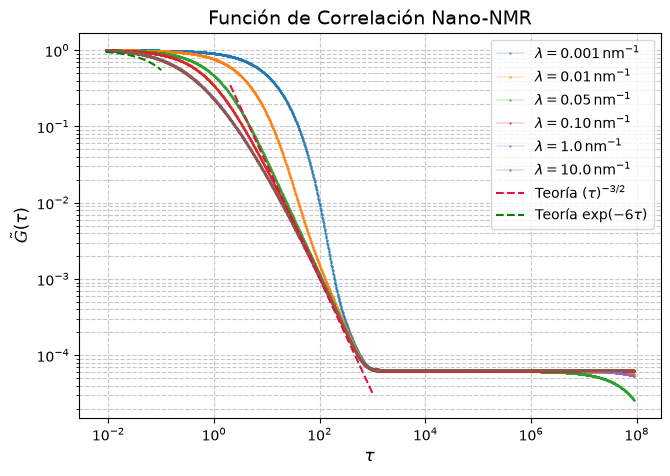

In [14]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, df.G_lam1/df.G_lam1[0], "o-", label=r"$\lambda=0.001\,\text{nm}^{-1}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_lam10/df.G_lam10[0], "o-", label=r"$\lambda=0.01\,\text{nm}^{-1}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_lam50/df.G_lam50[0], "o-", label=r"$\lambda=0.05\,\text{nm}^{-1}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_lam100/df.G_lam100[0], "o-", label=r"$\lambda=0.10\,\text{nm}^{-1}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_lam1000/df.G_lam1000[0], "o-", label=r"$\lambda=1.0\,\text{nm}^{-1}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_lam10000/df.G_lam10000[0], "o-", label=r"$\lambda=10.0\,\text{nm}^{-1}$", markersize=0.5, linewidth=0.25)
plt.plot(tau_values[(tau_values>=2)&(tau_values<=1000)], tau_values[(tau_values>=2)&(tau_values<=1000)]**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values[(tau_values<=0.1)], np.exp(-6*tau_values[(tau_values<=0.1)]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_lambdaVariation.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

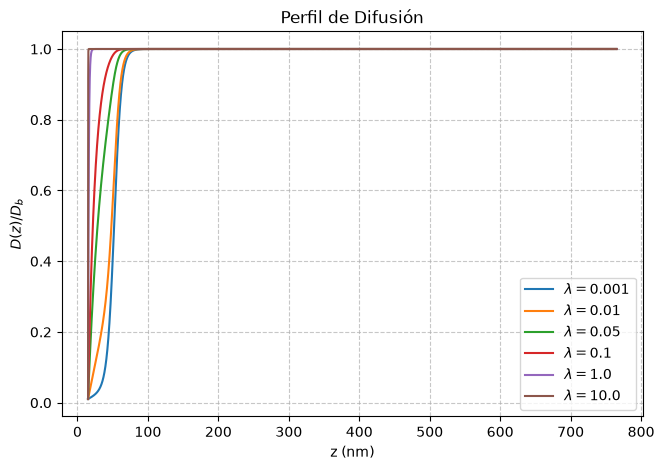

In [15]:
plt.figure(figsize=(7.5,5))
for lam in lambda_list:
    D_values=D(z,lam)
    plt.plot(z, D_values/D0,label=rf"$\lambda={lam}$", lw=1.5)
plt.xlabel('z (nm)')
plt.ylabel(r'$D(z)/D_b$')
plt.title('Perfil de Difusión')
plt.grid(ls='--', alpha=0.7)
plt.legend()
plt.savefig('figuras/Dz_profile_lambdaVariation.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Conclusiones

El barrido sobre $\lambda$ muestra que la longitud característica de recuperación de $D(z)$ es determinante en el perfil de $\tilde{G}(\tau)$:

- Para $\lambda$ pequeño ($\ll 1/d$), la difusividad permanece próxima a $D_s$ en una región extensa, retrasando la aparición del comportamiento bulk y deprimiendo $G(t)$ a tiempos intermedios.
- Para $\lambda$ grande ($\gg 1/d$), la recuperación ocurre dentro de pocos nanómetros de la superficie, haciendo que el perfil sea efectivamente homogéneo y $G(t)$ converja al resultado bulk.
- El perfil $D(z)/D_b$ confirma visualmente la extensión de la capa de baja difusividad en función de $\lambda$.

Este parámetro puede estimarse comparando la forma de $G(t)$ experimental con las curvas calculadas, actuando como huella dactilar de la estructura molecular de la capa superficial.